# What You Want Me to Stay? - KKBox Churn Prediction

*Exploratory Data Analysis*

![EDA](https://i.imgur.com/VTQ0TtT.jpg)
*Image source: devopedia.org*

## Table of Contents

1. Target
2. Members
3. Transactions
4. User logs
5. Dates
6. Bivariate
7. Conclusions

![KKBox challenge](https://i.imgur.com/qIF0TVJ.jpg)
*https://www.kaggle.com/c/kkbox-churn-prediction-challenge*

In [6]:
import sys; print(sys.executable)
import pandas, polars, pyarrow; print("ok")

/home/alejandropenagos/Escritorio/Alejandro/Machine Learning/customer-churn-prediction/workshops/.venv/bin/python
ok


## Introduction

This is the Exploratory Data Analysis of the WSDM - KKBox's Churn Prediction Challenge using Python. WSDM (pronounced "wisdom") is one of the premier conferences on web-inspired research involving search and data mining. WSDM hosted a challenge to build an algorithm that predicts whether a subscription user will churn using a donated dataset from KKBOX. For a subscription business, accurately predicting churn is critical to long-term success. Even slight variations in churn can drastically affect profits.

KKBOX is Asia's leading music streaming service, holding the world's most comprehensive Asia-Pop music library with over 30 million tracks. They offer a generous, unlimited version of their service to millions of people, supported by advertising and paid subscriptions. Currently, the company uses survival analysis techniques to determine the residual membership lifetime for each subscriber. By adopting different methods, KKBOX anticipates they'll discover new insights to why users leave so they can be proactive in keeping users dancing.

The dataset comes in 5 files:

- `train_v2.csv`
- `transactions_v2.csv`
- `user_logs_v2.csv`
- `members_v3.csv`
- `sample_submission_v2.csv`

**References**

- https://www.kaggle.com/headsortails/should-i-stay-or-should-i-go-kkbox-eda
- https://www.kaggle.com/c/kkbox-churn-prediction-challenge
- https://stackoverflow.com/questions/40347689/dataframe-describe-suppress-scientific-notation
- https://www.geeksforgeeks.org/python-working-with-date-and-time-using-pandas/

### Loading libraries

In [7]:
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
import warnings

# The feature pipeline (plan 05, phase 0.5) converts data/*.csv.7z to data/parquet/*.parquet once.
DATA_DIR = Path("../data")
PARQUET_DIR = DATA_DIR / "parquet"

sns.set()
warnings.filterwarnings("ignore")

In [ ]:
import sys

# Make the `w1` package importable when the notebook runs from `workshops/w1`.
sys.path.insert(0, str(Path.cwd().parent))

from w1.src.data_processing.utils import convert_raw_to_parquet

# Raw archives ship as data/*.csv.7z. Convert them once to data/parquet/*.parquet
# (the schema/columns contract lives in src/data_processing/schemas.py).
convert_raw_to_parquet(DATA_DIR)


In [9]:
PCTS = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 98, 99, 99.5, 99.99, 99.999, 100]


def tabla_percentiles(serie):
    return pd.DataFrame(np.percentile(serie, PCTS), index=PCTS, columns=["valor"])

## 1. Target

In [10]:
train_data = pl.read_parquet(PARQUET_DIR / "train_v2.parquet").to_pandas()

In [11]:
train_data.head()

,msno,is_churn
0,ugx0CjOMzazClkFzU2xasmDZaoIqOUAZPsH1q0teWCg=,1
1,f/NmvEzHfhINFEYZTR05prUdr+E+3+oewvweYz9cCQE=,1
2,zLo9f73nGGT1p21ltZC3ChiRnAVvgibMyazbCxvWPcg=,1
3,8iF/+8HY8lJKFrTc7iR9ZYGCG2Ecrogbc2Vy5YhsfhQ=,1
4,K6fja4+jmoZ5xG6BypqX80Uw/XKpMgrEMdG2edFOxnA=,1


`train_data` contains two columns: `msno` (a long user id) and `is_churn` (our target variable).

In [12]:
train_data.describe()

,is_churn
count,970960.000000
mean,0.089942
std,0.286099
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,1.000000


Our training dataset contains 970,960 rows with only two possible values (0 and 1). No abrupt value appears in this dataframe.

In [13]:
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 970960 entries, 0 to 970959
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype
---  ------    --------------   -----
 0   msno      970960 non-null  str  
 1   is_churn  970960 non-null  int8 
dtypes: int8(1), str(1)
memory usage: 49.1 MB


There is no null value present in the dataframe. This dataframe takes relatively less memory than the others. Note that binary values are stored as `int64`, which wastes memory; this will be optimized in the data preprocessing step.

### Plotting count vs is_churn to check the balance in the dataset

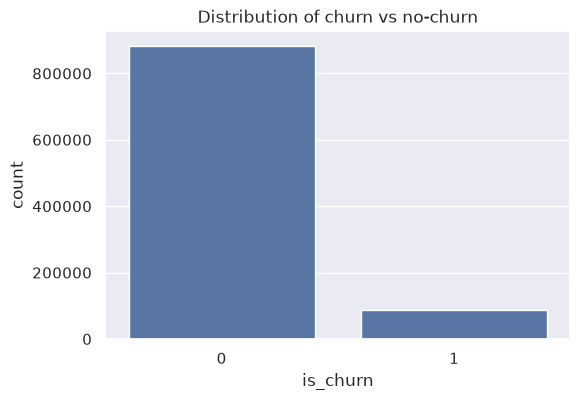

In [14]:
plt.figure(figsize=(6, 4))
sns.countplot(x=train_data["is_churn"])
plt.title("Distribution of churn vs no-churn")
plt.xlabel("is_churn")
plt.ylabel("count")
plt.show()

For a business, having few churn users is great, but it makes our dataset imbalanced.

In [15]:
counts = train_data["is_churn"].value_counts()
percents = train_data["is_churn"].value_counts(normalize=True)
no_churn, churn = counts[0], counts[1]

print("Total number of data points in train_v2.csv:", counts.sum())
print("No-churn data points:", no_churn)
print("Churn data points:", churn)
print("No-churn share: {:.3f}%".format(percents[0] * 100))
print("Churn share: {:.3f}%".format(percents[1] * 100))

Total number of data points in train_v2.csv: 970960
No-churn data points: 883630
Churn data points: 87330
No-churn share: 91.006%
Churn share: 8.994%


In [16]:
train_data[train_data["is_churn"].isnull()]

,msno,is_churn


**Target.**

`train_v2` has 970,960 users and no null values. 91% renew and 9% churn, so the dataset is highly imbalanced. That is why we evaluate with log-loss, F1 and the confusion matrix instead of accuracy. `is_churn` fits in `int8`.

## 2. Members

In [17]:
# members_v3.parquet; member.csv and member_v2.csv were replaced by the competition sponsors
member_data = pl.read_parquet(PARQUET_DIR / "members_v3.parquet").to_pandas()
member_data["registration_init_time"] = pd.to_datetime(
    member_data["registration_init_time"].astype(str), format="%Y%m%d")

In [18]:
member_data.head()

,msno,city,registered_via,bd,registration_init_time,gender
0,Rb9UwLQTrxzBVwCB6+bCcSQWZ9JiNLC9dXtM1oEsZA8=,1,11,0,2011-09-11,NaN
1,+tJonkh+O1CA796Fm5X60UMOtB6POHAwPjbTRVl/EuU=,1,7,0,2011-09-14,NaN
2,cV358ssn7a0f7jZOwGNWS07wCKVqxyiImJUX6xcIwKw=,1,11,0,2011-09-15,NaN
3,9bzDeJP6sQodK73K5CBlJ6fgIQzPeLnRl0p5B77XP+g=,1,11,0,2011-09-15,NaN
4,WFLY3s7z4EZsieHCt63XrsdtfTEmJ+2PnnKLH5GY4Tk=,6,9,32,2011-09-15,female


This dataframe contains 6 columns. Gender has NaN values, `registration_init_time` is a datetime feature, and gender is given as a string, so label encoding should be used.

In [19]:
member_data.shape  # more users than in our training set

(6769473, 6)

In [20]:
member_data.describe().apply(lambda s: s.apply(lambda x: format(x, "f")))

,city,registered_via,bd,registration_init_time
count,6769473.000000,6769473.000000,6769473.000000,6769473.000000
mean,3.847358,5.253069,9.795794,f
min,1.000000,-1.000000,-7168.000000,f
25%,1.000000,4.000000,0.000000,f
50%,1.000000,4.000000,0.000000,f
75%,4.000000,7.000000,21.000000,f
max,22.000000,19.000000,2016.000000,f
std,5.478359,2.361398,17.925900,nan


The city feature has no outliers (minimum 1, maximum 22). `bd` (age) has outliers because there are negative and very high values. `registered_via` also contains a negative value.

In [21]:
member_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6769473 entries, 0 to 6769472
Data columns (total 6 columns):
 #   Column                  Dtype         
---  ------                  -----         
 0   msno                    str           
 1   city                    int8          
 2   registered_via          int8          
 3   bd                      int16         
 4   registration_init_time  datetime64[us]
 5   gender                  str           
dtypes: datetime64[us](1), int16(1), int8(2), str(2)
memory usage: 497.7 MB


Memory of this dataframe can also be optimized.

#### bd stands for age

In [22]:
print(member_data["city"].value_counts())
print("Total number of distinct cities:", member_data["city"].nunique())

city
1     4804326
5      385069
13     320978
4      246848
22     210407
15     190213
6      135200
14      89940
12      66843
9       47639
11      47489
8       45975
18      38039
10      32482
21      30837
17      27772
3       27282
7       11610
16       5092
20       4233
19       1199
Name: count, dtype: int64
Total number of distinct cities: 21


In [23]:
tabla_percentiles(member_data["city"])

,valor
0.000,1.0
10.000,1.0
20.000,1.0
30.000,1.0
40.000,1.0
50.000,1.0
60.000,1.0
70.000,1.0
80.000,5.0
90.000,13.0


City data has no outliers, with city 1 being the highest.

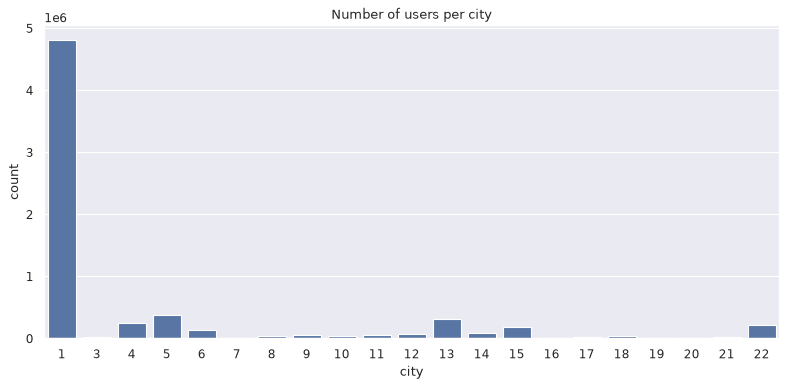

In [24]:
figure(num=None, figsize=(10, 5), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=member_data["city"])
plt.title("Number of users per city")
plt.xlabel("city")
plt.ylabel("count")
plt.tight_layout()
plt.show()

City 1 is dominant over all other cities. Other cities with more users are 4, 5, 13, 15 and 22.

In [25]:
print(member_data["bd"].describe())
print("maximum value:", member_data["bd"].max())
print("minimum value:", member_data["bd"].min())  # clearly contains outliers

count    6.769473e+06
mean     9.795794e+00
std      1.792590e+01
min     -7.168000e+03
25%      0.000000e+00
50%      0.000000e+00
75%      2.100000e+01
max      2.016000e+03
Name: bd, dtype: float64
maximum value: 2016
minimum value: -7168


In [26]:
# percentiles because the maximum values of these features are unusually high
tabla_percentiles(member_data["bd"])

,valor
0.000,-7168.0
10.000,0.0
20.000,0.0
30.000,0.0
40.000,0.0
50.000,0.0
60.000,0.0
70.000,18.0
80.000,25.0
90.000,33.0


The 50th percentile of age is 0, meaning there is little age data. The 75th percentile is 21, so youngsters are more frequent. There are outliers in the data.

### Plotting

1. counts vs `bd` to find which age is most present
2. counts vs `registered_via` to find which method is more favourable
3. counts vs `gender` to find which gender is most present
4. heatmap of `member_data` to see which values are missing

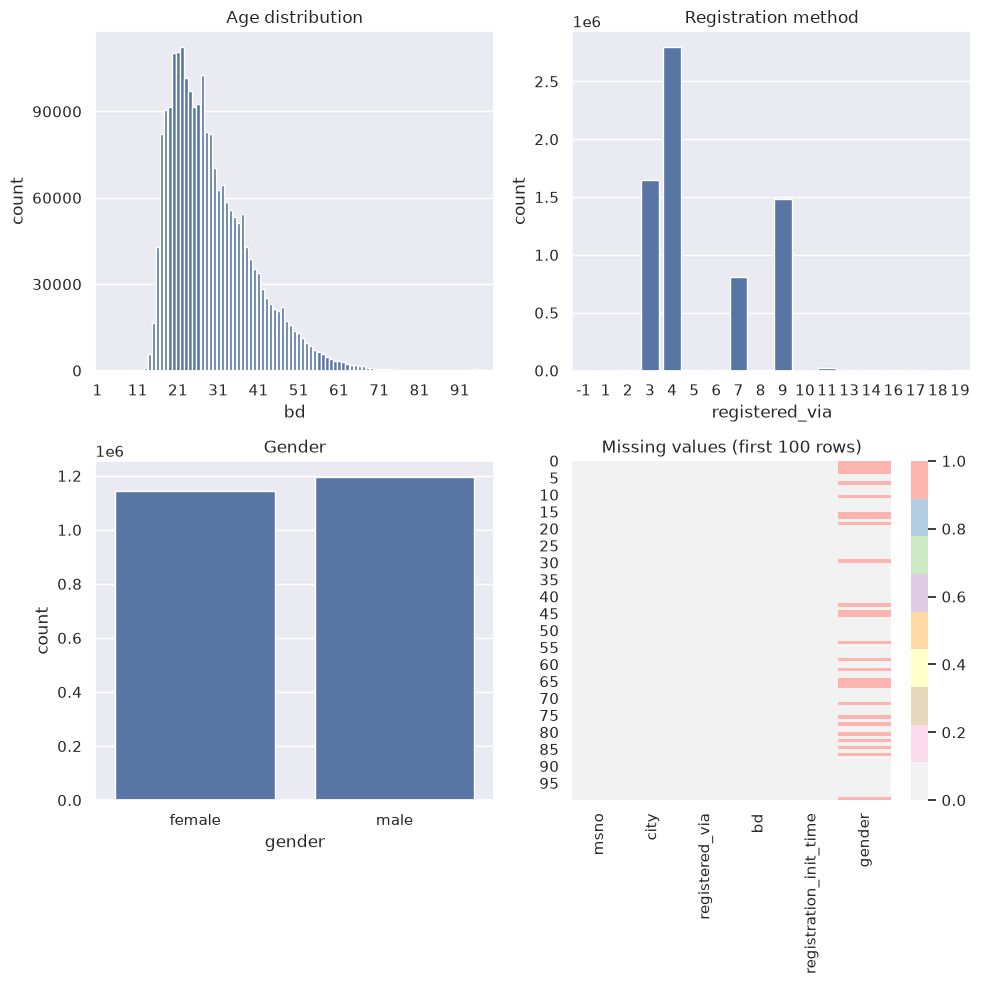

In [27]:
plt.figure(figsize=(10, 10))
plt.subplot(221)
sns.countplot(x=member_data["bd"][member_data["bd"] > 0][member_data["bd"] < 100])  # masking to avoid outliers
plt.title("Age distribution")
plt.xlabel("bd")
plt.ylabel("count")
plt.xticks(np.arange(0, 100, 10))
plt.yticks(np.arange(0, 120000, 30000))
plt.subplot(222)
sns.countplot(x=member_data["registered_via"])
plt.title("Registration method")
plt.xlabel("registered_via")
plt.ylabel("count")
plt.subplot(223)
sns.countplot(x=member_data["gender"])
plt.title("Gender")
plt.xlabel("gender")
plt.ylabel("count")
plt.subplot(224)
sns.heatmap(member_data[:100].isnull(), cmap="Pastel1_r")
plt.title("Missing values (first 100 rows)")
plt.tight_layout()
plt.show()

There is a peak in the age plot. There are some favourite/most-used registration methods. The gender plot is approximately balanced. Only gender data is missing (null).

Gender can be neglected because most values are unknown and the known ones are almost equally distributed. Methods 3, 4, 7 and 9 are preferred. As feature engineering we can build a flag for whether `registered_via` comes from a most-used method, and bin the age into ranges.

In [28]:
member_data["registered_via"].nunique()

18

In [29]:
member_data["msno"].nunique()

6769473

In [30]:
member_data["registered_via"].value_counts()

registered_via
 4     2793213
 3     1643208
 9     1482863
 7      805895
 11      25047
 13       5455
 8        3982
 5        3115
 17       1494
 2        1452
 6        1213
 19        974
 16        888
 14        615
 1          43
 10         10
 18          5
-1           1
Name: count, dtype: int64

In [31]:
tabla_percentiles(member_data["registered_via"])

,valor
0.000,-1.0
10.000,3.0
20.000,3.0
30.000,4.0
40.000,4.0
50.000,4.0
60.000,4.0
70.000,7.0
80.000,9.0
90.000,9.0


**Members.**

- `city`: there are 21 cities and city 1 dominates. Cities 4, 5, 13, 15 and 22 follow.
- `bd` (age): contains negative values and values greater than 100. The median is 0 because missing age was stored as 0. Valid values concentrate on young ages.
- `gender`: almost all values are null, and among known values the split is ~50/50, so it adds little.
- `registered_via`: there are 18 methods. The most used are 3, 4, 7 and 9, and invalid negative values appear.
- Proposed features: a flag for popular registration method and age grouped into ranges.

## 3. Transactions

**Note:** transaction data comes in two parts; only the second part is used for visualisation.

In [32]:
# transactions_v2.parquet; both transaction files are used in preprocessing
transaction_data = pl.read_parquet(PARQUET_DIR / "transactions_v2.parquet").to_pandas()
for col in ("transaction_date", "membership_expire_date"):
    transaction_data[col] = pd.to_datetime(
        transaction_data[col].astype(str), format="%Y%m%d")

In [33]:
transaction_data.head()

,msno,payment_method_id,payment_plan_days,plan_list_price,actual_amount_paid,is_auto_renew,transaction_date,membership_expire_date,is_cancel
0,++6eU4LsQ3UQ20ILS7d99XK8WbiVgbyYL4FUgzZR134=,32,90,298,298,0,2017-01-31,2017-05-04,0
1,++lvGPJOinuin/8esghpnqdljm6NXS8m8Zwchc7gOeA=,41,30,149,149,1,2015-08-09,2019-04-12,0
2,+/GXNtXWQVfKrEDqYAzcSw2xSPYMKWNj22m+5XkVQZc=,36,30,180,180,1,2017-03-03,2017-04-22,0
3,+/w1UrZwyka4C9oNH3+Q8fUf3fD8R3EwWrx57ODIsqk=,36,30,180,180,1,2017-03-29,2017-03-31,1
4,+00PGzKTYqtnb65mPKPyeHXcZEwqiEzktpQksaaSC3c=,41,30,99,99,1,2017-03-23,2017-04-23,0


This dataframe has 9 features. There are no string features except the id (`msno`).

In [34]:
transaction_data.describe().apply(lambda s: s.apply(lambda x: format(x, "f")))

,payment_method_id,payment_plan_days,plan_list_price,actual_amount_paid,is_auto_renew,transaction_date,membership_expire_date,is_cancel
count,1431009.000000,1431009.000000,1431009.000000,1431009.000000,1431009.000000,1431009.000000,1431009.000000,1431009.000000
mean,37.918355,66.017696,281.787035,281.317241,0.785303,f,f,0.024551
min,2.000000,0.000000,0.000000,0.000000,0.000000,f,f,0.000000
25%,36.000000,30.000000,99.000000,99.000000,1.000000,f,f,0.000000
50%,40.000000,30.000000,149.000000,149.000000,1.000000,f,f,0.000000
75%,41.000000,30.000000,149.000000,149.000000,1.000000,f,f,0.000000
max,41.000000,450.000000,2000.000000,2000.000000,1.000000,f,f,1.000000
std,4.964805,102.486396,435.186138,435.419950,0.410612,nan,nan,0.154753


No outliers in `is_auto_renew` or `is_cancel`. The high-level statistics of `actual_amount_paid` and `plan_list_price` are similar, but their means differ, so there is some difference between them.

In [35]:
transaction_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1431009 entries, 0 to 1431008
Data columns (total 9 columns):
 #   Column                  Non-Null Count    Dtype         
---  ------                  --------------    -----         
 0   msno                    1431009 non-null  str           
 1   payment_method_id       1431009 non-null  int8          
 2   payment_plan_days       1431009 non-null  int16         
 3   plan_list_price         1431009 non-null  int16         
 4   actual_amount_paid      1431009 non-null  int16         
 5   is_auto_renew           1431009 non-null  int8          
 6   transaction_date        1431009 non-null  datetime64[us]
 7   membership_expire_date  1431009 non-null  datetime64[us]
 8   is_cancel               1431009 non-null  int8          
dtypes: datetime64[us](2), int16(3), int8(3), str(1)
memory usage: 105.1 MB


The same memory optimization can be used.

In [36]:
transaction_data.shape

(1431009, 9)

### Plotting count vs payment_method_id

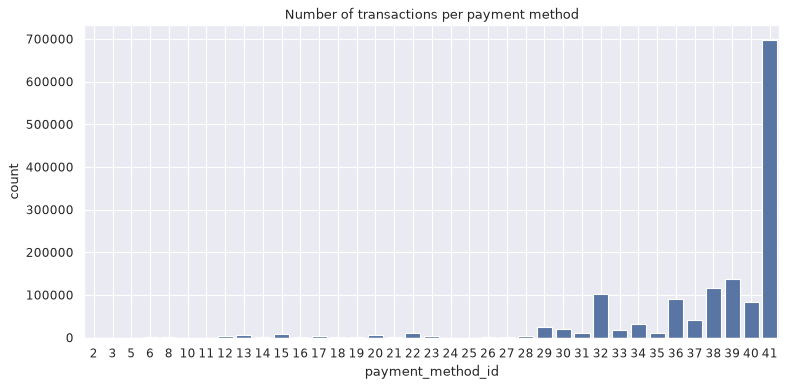

In [37]:
figure(num=None, figsize=(10, 5), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=transaction_data["payment_method_id"])
plt.title("Number of transactions per payment method")
plt.xlabel("payment_method_id")
plt.ylabel("count")
plt.tight_layout()
plt.grid(True)
plt.show()

In [38]:
tabla_percentiles(transaction_data["payment_method_id"])

,valor
0.000,2.0
10.000,32.0
20.000,36.0
30.000,38.0
40.000,39.0
50.000,40.0
60.000,41.0
70.000,41.0
80.000,41.0
90.000,41.0


The later payment methods are more popular; method 41 is the most used. Since it is an int, it has to be encoded. There are large category values, so one-hot encoding would create sparsity. As feature engineering we can flag whether the user uses a more popular method.

### Plotting count vs payment_plan_days

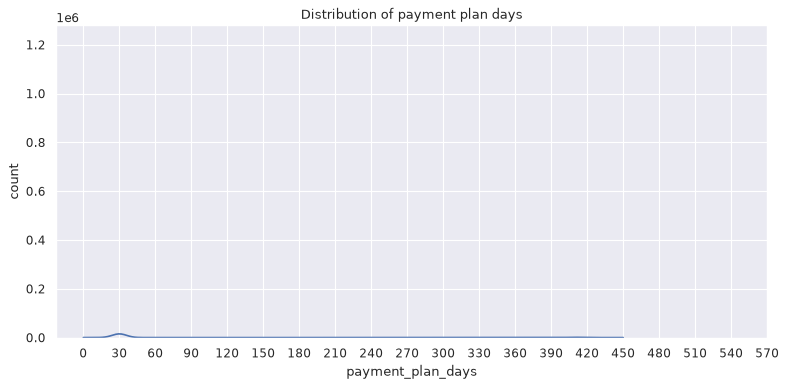

In [39]:
figure(num=None, figsize=(10, 5), dpi=80, facecolor="w", edgecolor="k")
sns.histplot(x=transaction_data["payment_plan_days"], kde=True)
plt.title("Distribution of payment plan days")
plt.xlabel("payment_plan_days")
plt.ylabel("count")
plt.xticks(range(0, 600, 30))
plt.tight_layout()
plt.show()

In [40]:
tabla_percentiles(transaction_data["payment_plan_days"])

,valor
0.000,0.0
10.000,30.0
20.000,30.0
30.000,30.0
40.000,30.0
50.000,30.0
60.000,30.0
70.000,30.0
80.000,30.0
90.000,195.0


Almost everyone takes a 30-day plan. People who take a 420-day plan are less likely to churn. We can build an indicator of whether the plan is above 150 days.

### Plotting count vs plan_list_price

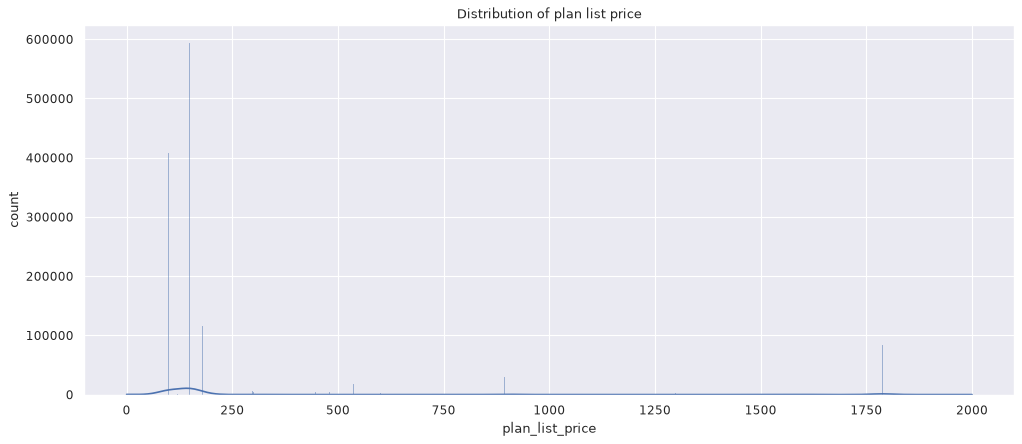

In [41]:
figure(num=None, figsize=(15, 6), dpi=80, facecolor="w", edgecolor="k")
sns.histplot(x=transaction_data["plan_list_price"], kde=True)
plt.title("Distribution of plan list price")
plt.xlabel("plan_list_price")
plt.ylabel("count")
plt.show()

In [42]:
tabla_percentiles(transaction_data["plan_list_price"])

,valor
0.000,0.0
10.000,99.0
20.000,99.0
30.000,100.0
40.000,149.0
50.000,149.0
60.000,149.0
70.000,149.0
80.000,180.0
90.000,799.0


Some people choose a very high price. These passionate users tend not to churn, so an indicator can be used.

### Plotting count vs actual amount paid

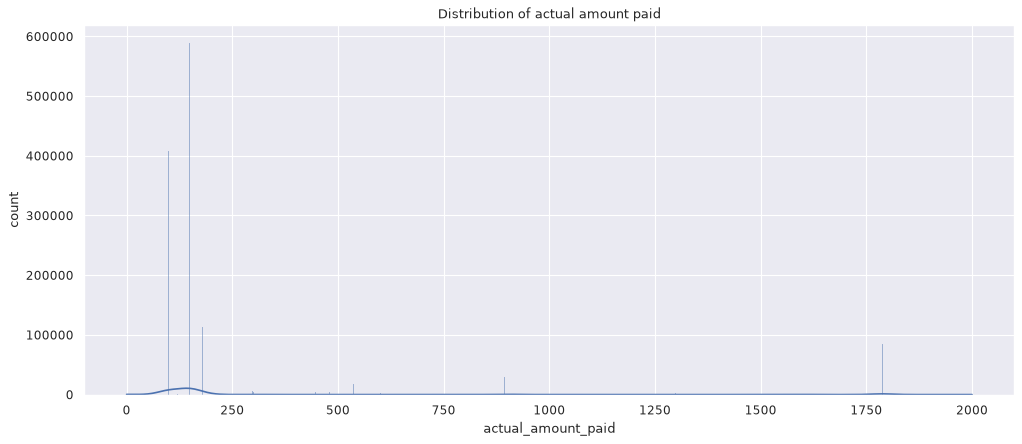

In [43]:
figure(num=None, figsize=(15, 6), dpi=80, facecolor="w", edgecolor="k")
sns.histplot(x=transaction_data["actual_amount_paid"], kde=True)
plt.title("Distribution of actual amount paid")
plt.xlabel("actual_amount_paid")
plt.ylabel("count")
plt.show()

In [44]:
tabla_percentiles(transaction_data["actual_amount_paid"])

,valor
0.000,0.0
10.000,99.0
20.000,99.0
30.000,99.0
40.000,149.0
50.000,149.0
60.000,149.0
70.000,149.0
80.000,180.0
90.000,799.0


The actual amount paid and plan list price graphs are almost identical. No obvious distinction can be made; a deeper study is required.

### Plots between

1. counts and `is_auto_renew`
2. counts and `is_cancel`

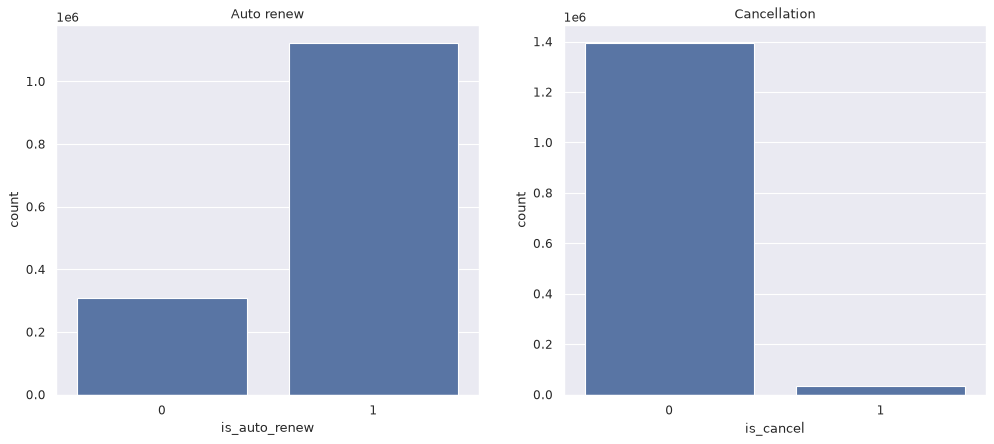

In [45]:
figure(num=None, figsize=(15, 6), dpi=80, facecolor="w", edgecolor="k")
plt.subplot(121)
sns.countplot(x=transaction_data["is_auto_renew"])
plt.title("Auto renew")
plt.xlabel("is_auto_renew")
plt.ylabel("count")
plt.subplot(122)
sns.countplot(x=transaction_data["is_cancel"])
plt.title("Cancellation")
plt.xlabel("is_cancel")
plt.ylabel("count")
plt.show()

**Transactions.**

- `payment_method_id`: 41 is the most used. Because there are many categories, a flag is better than one-hot.
- `payment_plan_days`: almost all plans are 30 days and there are long plans (up to ~450). A long plan indicates a committed user.
- `plan_list_price` and `actual_amount_paid` are distributed almost identically. In the rows where they differ, the difference concentrates on 30, 149 and 180, and some users pay more than the list price. That difference is a feature.
- `is_auto_renew` is active in most cases and `is_cancel` is infrequent.

There are two date features, `transaction_date` and `membership_expire_date`, used to decide whether the user churned: if there is no new subscription within 30 days, the customer is considered churned.

Since theoretical and actual price look almost the same at first, let's go deeper to check whether there is a difference.

In [46]:
(transaction_data["actual_amount_paid"] != transaction_data["plan_list_price"]).value_counts()

False    1419106
True       11903
Name: count, dtype: int64

There is some difference between the actual and theoretical price paid by users.

In [47]:
temp_data = transaction_data[transaction_data["actual_amount_paid"] != transaction_data["plan_list_price"]]
# checking only where there is actually a difference

### Plot count vs difference in the actual and paid amount

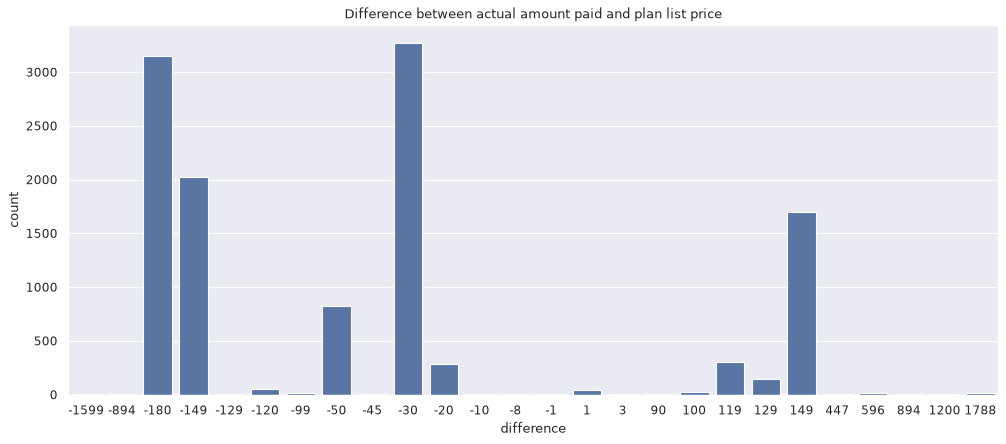

In [48]:
figure(num=None, figsize=(15, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=temp_data["actual_amount_paid"] - temp_data["plan_list_price"])
plt.title("Difference between actual amount paid and plan list price")
plt.xlabel("difference")
plt.ylabel("count")
plt.show()

Most people got a difference of 30, 149 and 180. The most interesting thing is that people are paying more than they should have.

## 4. User logs

`user_logs_v2.parquet` is a huge file; a 1M-row subset is used for visualization.

In [49]:
# user_logs_v2.parquet is huge; a 1M-row sample is enough for visualisation.
user_logs = pl.read_parquet(PARQUET_DIR / "user_logs_v2.parquet", n_rows=1_000_000).to_pandas()
user_logs["date"] = pd.to_datetime(user_logs["date"].astype(str), format="%Y%m%d")

In [50]:
user_logs.head()

,msno,date,num_25,num_50,num_75,num_985,num_100,num_unq,total_secs
0,u9E91QDTvHLq6NXjEaWv8u4QIqhrHk72kE+w31Gnhdg=,2017-03-31,8,4,0,1,21,18,6309.273
1,nTeWW/eOZA/UHKdD5L7DEqKKFTjaAj3ALLPoAWsU8n0=,2017-03-30,2,2,1,0,9,11,2390.699
2,2UqkWXwZbIjs03dHLU9KHJNNEvEkZVzm69f3jCS+uLI=,2017-03-31,52,3,5,3,84,110,23203.337
3,ycwLc+m2O0a85jSLALtr941AaZt9ai8Qwlg9n0Nql5U=,2017-03-31,176,4,2,2,19,191,7100.454
4,EGcbTofOSOkMmQyN1NMLxHEXJ1yV3t/JdhGwQ9wXjnI=,2017-03-31,2,1,0,1,112,93,28401.558


Contains 9 columns, all numerical features. Since these are user logs, more than one entry per user is very common. Logs are divided by days.

In [51]:
user_logs.shape  # just 1 month of data; the initial log file is ~32 GB

(1000000, 9)

In [52]:
user_logs.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 9 columns):
 #   Column      Non-Null Count    Dtype         
---  ------      --------------    -----         
 0   msno        1000000 non-null  str           
 1   date        1000000 non-null  datetime64[us]
 2   num_25      1000000 non-null  int32         
 3   num_50      1000000 non-null  int32         
 4   num_75      1000000 non-null  int32         
 5   num_985     1000000 non-null  int32         
 6   num_100     1000000 non-null  int32         
 7   num_unq     1000000 non-null  int32         
 8   total_secs  1000000 non-null  float64       
dtypes: datetime64[us](1), float64(1), int32(6), str(1)
memory usage: 87.7 MB


Memory can be optimized.

In [53]:
user_logs.describe().apply(lambda s: s.apply(lambda x: format(x, "f")))

,date,num_25,num_50,num_75,num_985,num_100,num_unq,total_secs
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,f,6.195458,1.509556,0.943134,1.081309,30.304456,29.071834,7911.606792
min,f,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.023000
25%,f,0.000000,0.000000,0.000000,0.000000,7.000000,8.000000,1967.845750
50%,f,2.000000,1.000000,0.000000,0.000000,17.000000,19.000000,4598.790500
75%,f,7.000000,2.000000,1.000000,1.000000,37.000000,38.000000,9855.994000
max,f,2101.000000,558.000000,241.000000,957.000000,2120.000000,877.000000,515927.542000
std,nan,12.972856,3.953778,1.914086,3.587555,39.839431,32.037360,9641.563675


- `msno`: user id
- `date`: format %Y%m%d
- `num_25`: # of songs played less than 25% of the song length
- `num_50`: # of songs played between 25% to 50% of the song length
- `num_75`: # of songs played between 50% to 75% of the song length
- `num_985`: # of songs played between 75% to 98.5% of the song length
- `num_100`: # of songs played over 98.5% of the song length
- `num_unq`: # of unique songs played
- `total_secs`: total seconds played

For most users `num_25` and `num_100` are high while `num_50` and `num_75` are mostly low.

In [54]:
# percentiles because the maximum values of these features are unusually high
tabla_percentiles(user_logs["num_25"])

,valor
0.000,0.00000
10.000,0.00000
20.000,0.00000
30.000,1.00000
40.000,1.00000
50.000,2.00000
60.000,4.00000
70.000,5.00000
80.000,9.00000
90.000,16.00000


Clearly there are some outliers.

In [55]:
tabla_percentiles(user_logs["num_50"])

,valor
0.000,0.00000
10.000,0.00000
20.000,0.00000
30.000,0.00000
40.000,0.00000
50.000,1.00000
60.000,1.00000
70.000,1.00000
80.000,2.00000
90.000,4.00000


In [56]:
tabla_percentiles(user_logs["num_75"])

,valor
0.000,0.00000
10.000,0.00000
20.000,0.00000
30.000,0.00000
40.000,0.00000
50.000,0.00000
60.000,1.00000
70.000,1.00000
80.000,2.00000
90.000,3.00000


In [57]:
tabla_percentiles(user_logs["num_985"])

,valor
0.000,0.00000
10.000,0.00000
20.000,0.00000
30.000,0.00000
40.000,0.00000
50.000,0.00000
60.000,1.00000
70.000,1.00000
80.000,2.00000
90.000,3.00000


In [58]:
tabla_percentiles(user_logs["num_100"])

,valor
0.000,0.00000
10.000,2.00000
20.000,5.00000
30.000,8.00000
40.000,12.00000
50.000,17.00000
60.000,23.00000
70.000,31.00000
80.000,45.00000
90.000,76.00000


The conclusion from the dataframes above is that we need to set a threshold above some value because they look like outliers.

### Plots between

1. distribution of `num_25`
2. distribution of `num_50`
3. distribution of `num_75`
4. distribution of `num_985`
5. distribution of `num_100`

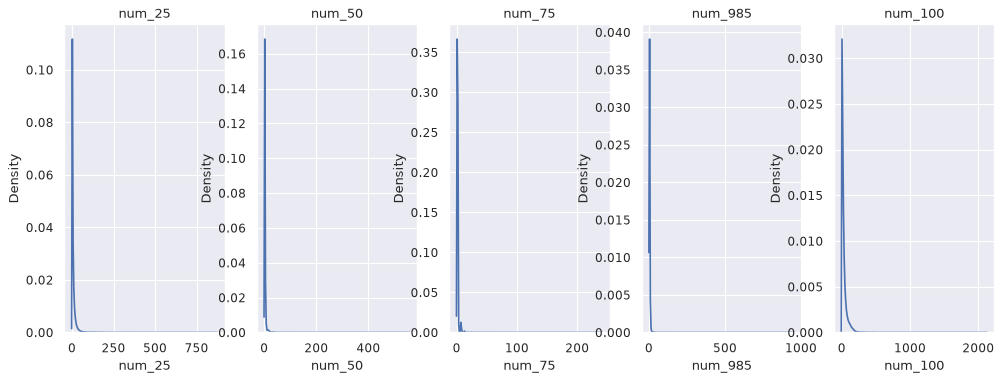

In [59]:
figure(num=None, figsize=(15, 5), dpi=80, facecolor="w", edgecolor="k")
plt.subplot(151)
sns.kdeplot(x=user_logs["num_25"][user_logs["num_25"] < 1000])
plt.title("num_25")
plt.xlabel("num_25")
plt.subplot(152)
sns.kdeplot(x=user_logs["num_50"])
plt.title("num_50")
plt.xlabel("num_50")
plt.subplot(153)
sns.kdeplot(x=user_logs["num_75"])
plt.title("num_75")
plt.xlabel("num_75")
plt.subplot(154)
sns.kdeplot(x=user_logs["num_985"])
plt.title("num_985")
plt.xlabel("num_985")
plt.subplot(155)
sns.kdeplot(x=user_logs["num_100"])
plt.title("num_100")
plt.xlabel("num_100")
plt.show()

The pattern shows a rise, a fall and then a rise again in all five plots. The most interesting observation is that in almost all five graphs there is a minimum in the middle, i.e. the value rises again at the end.

This pattern is very obvious and common: most people listen to some songs. There are very few people who listen to 50-75% of a song; people either listen to less than 25% or to 100% of it. This shows how much a user loved a song.

### Plot between counts and entries per user

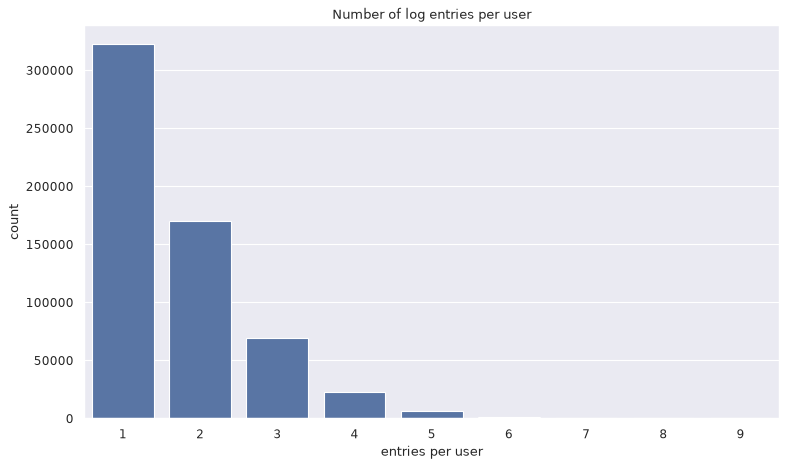

In [60]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=user_logs["msno"].value_counts().values)
plt.title("Number of log entries per user")
plt.xlabel("entries per user")
plt.ylabel("count")
plt.tight_layout()
plt.show()

It can be seen that either we have very little information about the user or we have a lot of it.

Listening to 1,200 songs in one day is not possible, so values above 1,200 can be considered outliers.

**User logs.**

- The `num_*` and `total_secs` variables have very long tails, so they must be clipped by percentile.
- Listening is bimodal: people skip the song before 25% or listen to it fully. This is a measure of affinity.
- The number of records per user is also bimodal: either very few or many.

## 5. Dates

*Let's do some date and time plots.*

![Time](https://i.imgur.com/xuo6LM8.png)

Date and time plots are very interesting.

**Note:** the plots below are for registration.

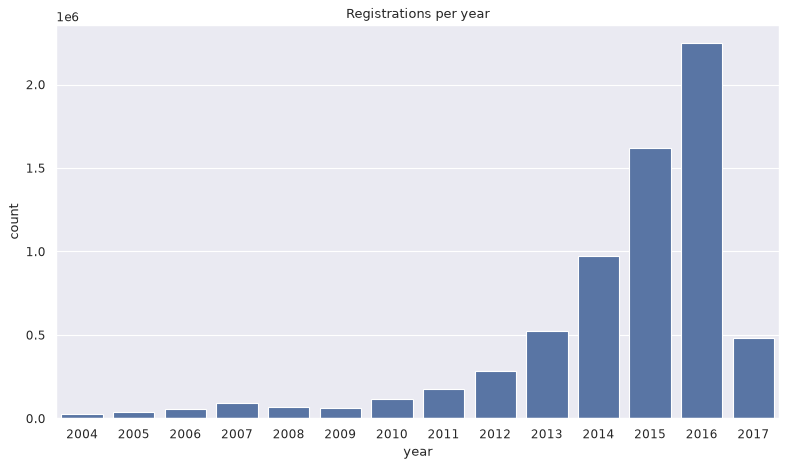

In [61]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=member_data["registration_init_time"].dt.year)
plt.title("Registrations per year")
plt.xlabel("year")
plt.ylabel("count")
plt.tight_layout()
plt.show()

An exponential growth is visible. Since we do not have complete data for 2017, we cannot comment on that part.

### Plot between count and registration month

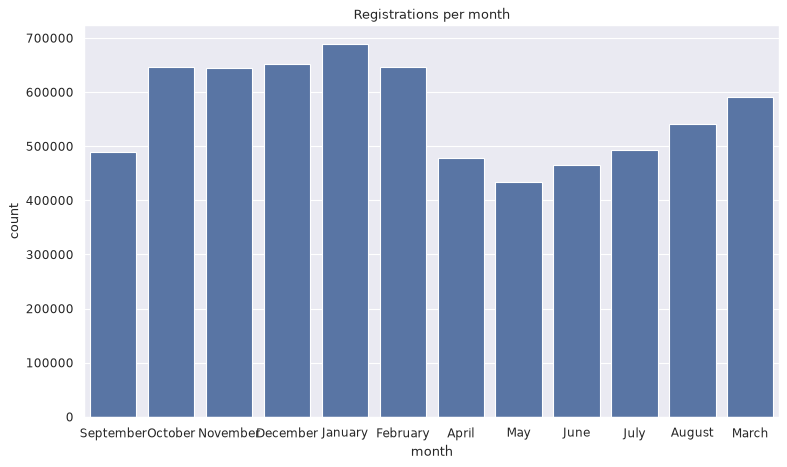

In [62]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=member_data["registration_init_time"].dt.month_name())
plt.title("Registrations per month")
plt.xlabel("month")
plt.ylabel("count")
plt.tight_layout()
plt.show()

People tend to register in the later months, i.e. at the end and start of the year.

### Plot between count and day of week

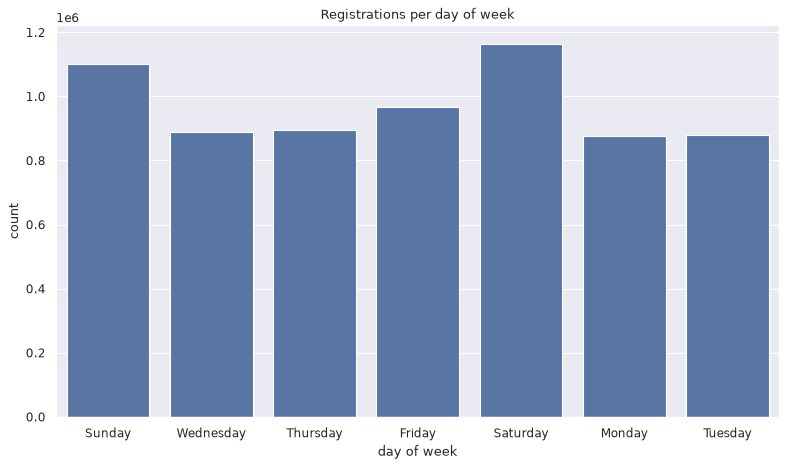

In [63]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=member_data["registration_init_time"].dt.day_name())
plt.title("Registrations per day of week")
plt.xlabel("day of week")
plt.ylabel("count")
plt.tight_layout()
plt.show()

In the initial years growth is slow, but later it increases very fast, with a dip in the last year. More people register on weekends (Saturday and Sunday). May, June and July have fewer registrations.

**Note:** the plots below are for transactions.

### Plot between count and transaction date, year-wise

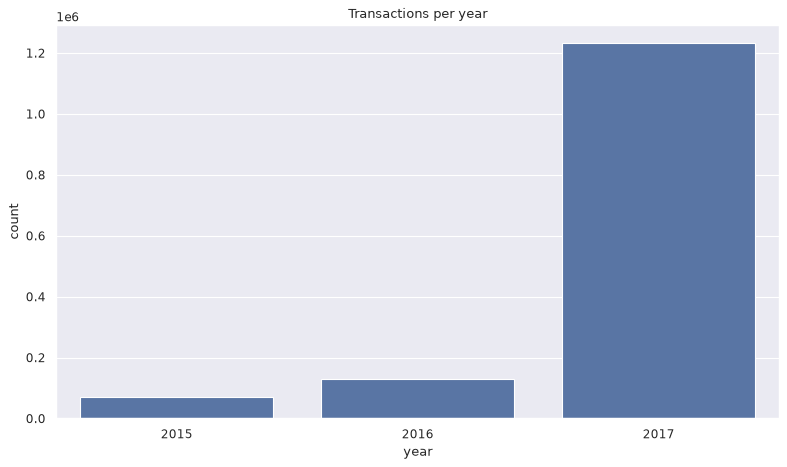

In [64]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=transaction_data["transaction_date"].dt.year)
plt.title("Transactions per year")
plt.xlabel("year")
plt.ylabel("count")
plt.tight_layout()
plt.show()

Since most people use a monthly subscription and we are given 2017 data, this graph is expected.

### Counts vs month of transaction date

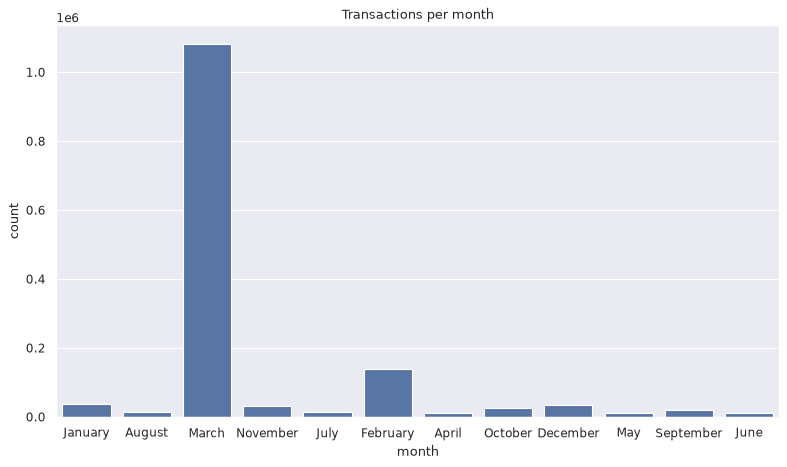

In [65]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=transaction_data["transaction_date"].dt.month_name())
plt.title("Transactions per month")
plt.xlabel("month")
plt.ylabel("count")
plt.tight_layout()
plt.show()

March data is unusually high because we are seeing March data. The plot changes if both transaction files are included.

### Plot between count and transaction date, day of week

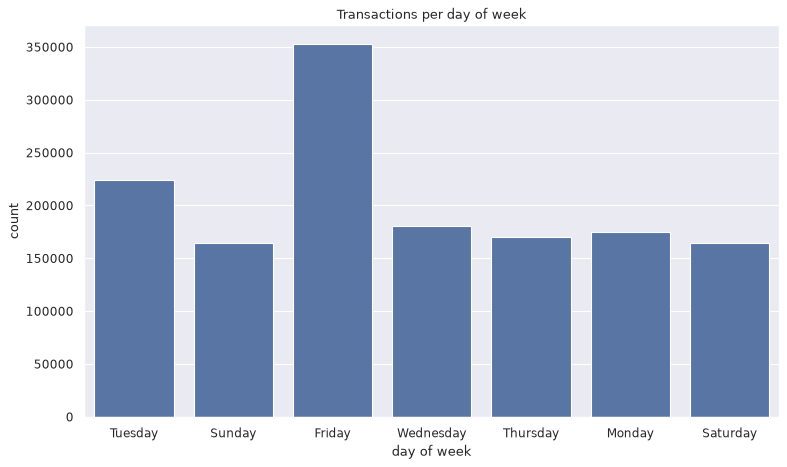

In [66]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=transaction_data["transaction_date"].dt.day_name())
plt.title("Transactions per day of week")
plt.xlabel("day of week")
plt.ylabel("count")
plt.tight_layout()
plt.show()

Most transactions happen in March, then February. Friday has the most transactions, and the number increases year by year.

**Note:** the plots below are for membership expiration date.

In [67]:
transaction_data["membership_expire_date"].dt.year.value_counts()

membership_expire_date
2017    1354731
2018      66549
2019       6735
2020       2074
2021        604
2022        143
2023         41
2024         32
2027         32
2026         20
2025         20
2016         11
2028         10
2036          1
2034          1
2030          1
2032          1
2033          1
2035          1
2031          1
Name: count, dtype: int64

In [68]:
tabla_percentiles(transaction_data["membership_expire_date"].dt.year)

,valor
0.000,2016.0
10.000,2017.0
20.000,2017.0
30.000,2017.0
40.000,2017.0
50.000,2017.0
60.000,2017.0
70.000,2017.0
80.000,2017.0
90.000,2017.0


Some people have an expiration date in 2018 or later. They are long-term users and have a low risk of churning.

### Plot between count and membership expire date, year-wise

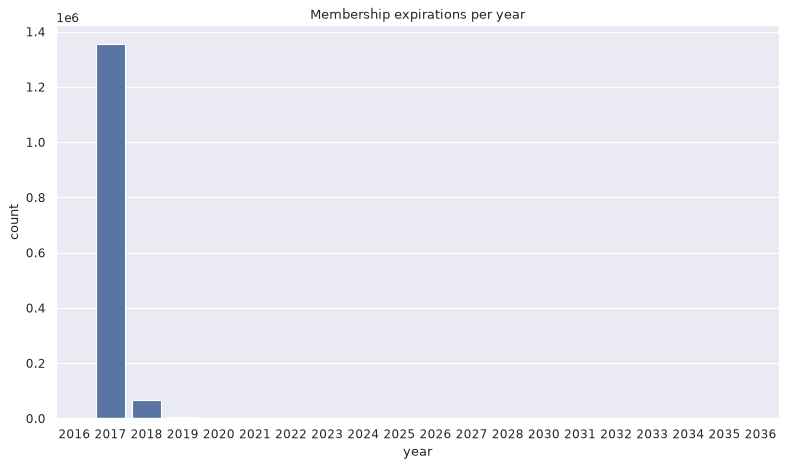

In [69]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=transaction_data["membership_expire_date"].dt.year)
plt.title("Membership expirations per year")
plt.xlabel("year")
plt.ylabel("count")
plt.tight_layout()
plt.show()

This plot is consistent with people taking monthly subscriptions, so their expiration date is in the same year.

In [70]:
transaction_data["membership_expire_date"].dt.month_name().value_counts()

membership_expire_date
April        1037972
May           142927
March          57106
June           39078
July           27782
August         26938
September      25030
October        18034
November       14913
January        14268
February       13532
December       13429
Name: count, dtype: int64

Most subscriptions end in April because this data is from March.

### Count and month of membership expire date

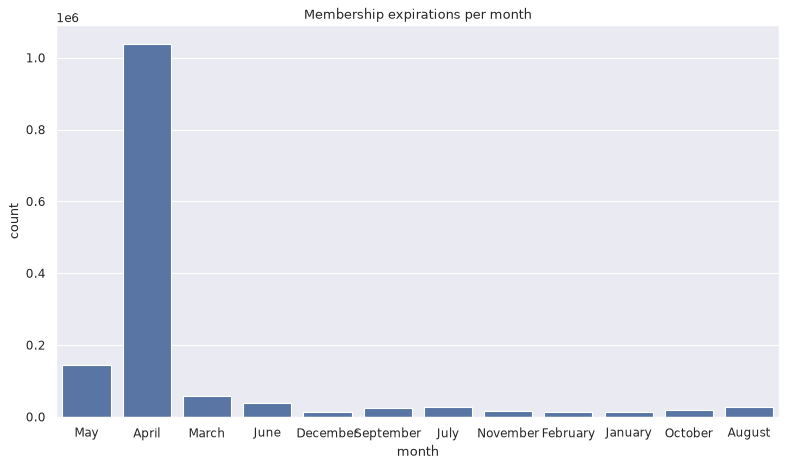

In [71]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=transaction_data["membership_expire_date"].dt.month_name())
plt.title("Membership expirations per month")
plt.xlabel("month")
plt.ylabel("count")
plt.tight_layout()
plt.show()

Since cancelling is not counted as churn, people whose subscription ends after April have a low risk of churning.

### Plot between count and membership expire date, day of week

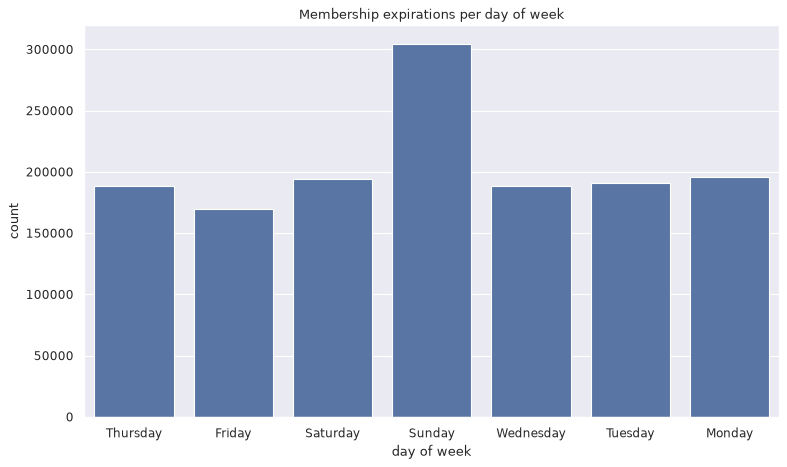

In [72]:
figure(num=None, figsize=(10, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=transaction_data["membership_expire_date"].dt.day_name())
plt.title("Membership expirations per day of week")
plt.xlabel("day of week")
plt.ylabel("count")
plt.tight_layout()
plt.show()

The expiration date is consistent with the transaction data; most customers transact within the month. Most subscriptions end within the same year, which shows people do not invest in long-term subscriptions. Sunday is the most likely day for a subscription to end.

### Plot between count and month of transaction

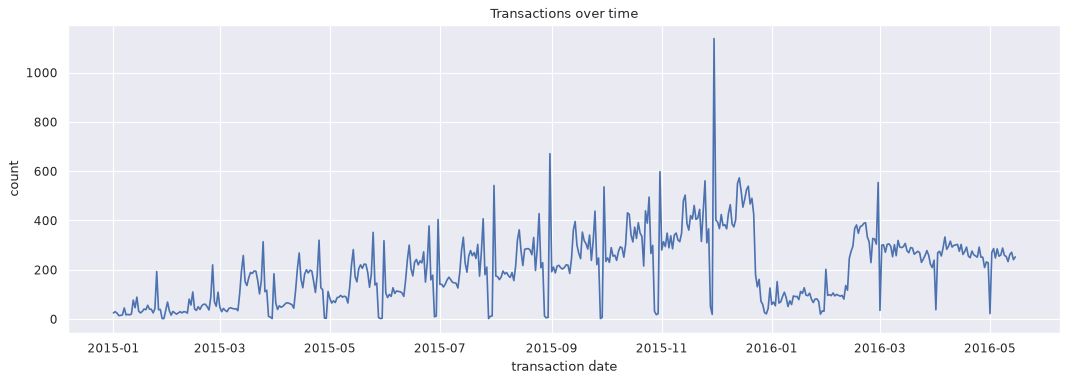

In [73]:
figure(num=None, figsize=(16, 5), dpi=80, facecolor="w", edgecolor="k")
plt.plot(transaction_data["transaction_date"].value_counts().sort_index()[:500])
plt.title("Transactions over time")
plt.xlabel("transaction date")
plt.ylabel("count")
plt.show()

There is a repeating pattern that grows with the year. The growth shows the company's business is increasing, and the repeating pattern shows customer behaviour. The graph below shows the same monthly pattern for the membership expiration date.

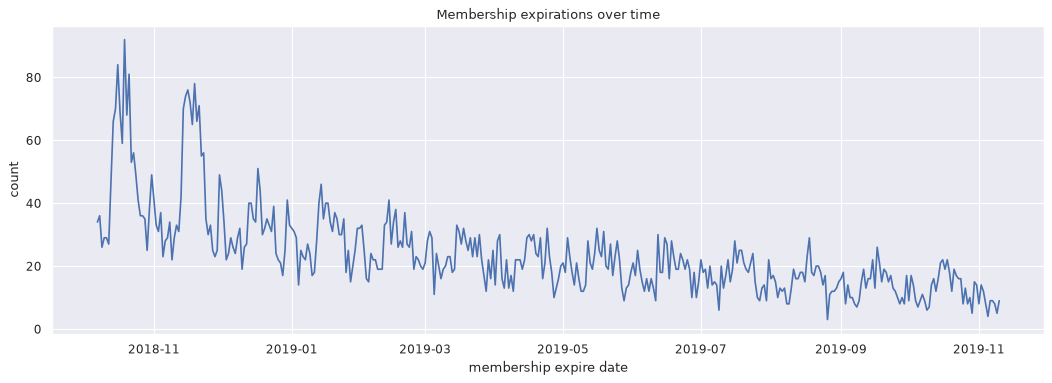

In [74]:
figure(num=None, figsize=(16, 5), dpi=80, facecolor="w", edgecolor="k")
plt.plot(transaction_data["membership_expire_date"].value_counts().sort_index()[600:1000])
plt.title("Membership expirations over time")
plt.xlabel("membership expire date")
plt.ylabel("count")
plt.show()

**Dates.**

- Registrations grow exponentially by year, there are fewer between May and July, and more on weekends.
- Transactions and expirations follow a monthly cycle that grows over time, which is the 30-day renewal cycle.
- Memberships that expire in 2018 or later belong to long-term users, with low churn risk.
- Conclusion: time carries information and must be turned into features (month, day of week, days to expiration).

## 6. Bivariate

### Features with respect to the target variable

In [75]:
# merging train data and member data
train_member = pd.merge(train_data, member_data, how="left", on="msno")

In [76]:
train_member.head()

,msno,is_churn,city,registered_via,bd,registration_init_time,gender
0,ugx0CjOMzazClkFzU2xasmDZaoIqOUAZPsH1q0teWCg=,1,5.0,3.0,28.0,2013-12-23,male
1,f/NmvEzHfhINFEYZTR05prUdr+E+3+oewvweYz9cCQE=,1,13.0,3.0,20.0,2013-12-23,male
2,zLo9f73nGGT1p21ltZC3ChiRnAVvgibMyazbCxvWPcg=,1,13.0,3.0,18.0,2013-12-27,male
3,8iF/+8HY8lJKFrTc7iR9ZYGCG2Ecrogbc2Vy5YhsfhQ=,1,1.0,7.0,0.0,2014-01-09,NaN
4,K6fja4+jmoZ5xG6BypqX80Uw/XKpMgrEMdG2edFOxnA=,1,13.0,7.0,35.0,2014-01-25,female


### Plot between

1. gender and count with respect to churn
2. registered_via and count with respect to churn

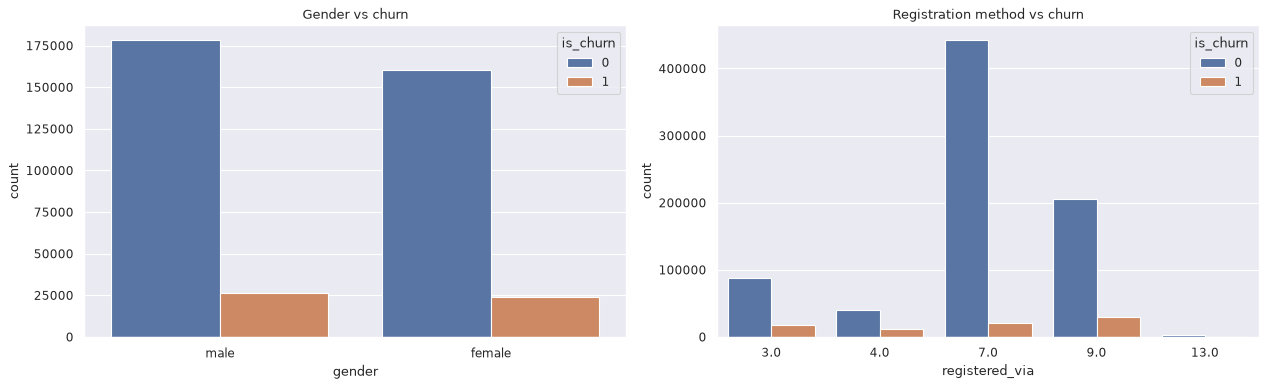

In [77]:
figure(num=None, figsize=(16, 5), dpi=80, facecolor="w", edgecolor="k")
plt.subplot(121)
sns.countplot(data=train_member, x="gender", hue="is_churn")
plt.title("Gender vs churn")
plt.xlabel("gender")
plt.ylabel("count")
plt.subplot(122)
sns.countplot(data=train_member, x="registered_via", hue="is_churn")
plt.title("Registration method vs churn")
plt.xlabel("registered_via")
plt.ylabel("count")
plt.tight_layout()
plt.show()

Gender has very little impact on churning. People who use method 9 have more churn, so we can create a flag for that.

### Plot between city and count with hue as churn

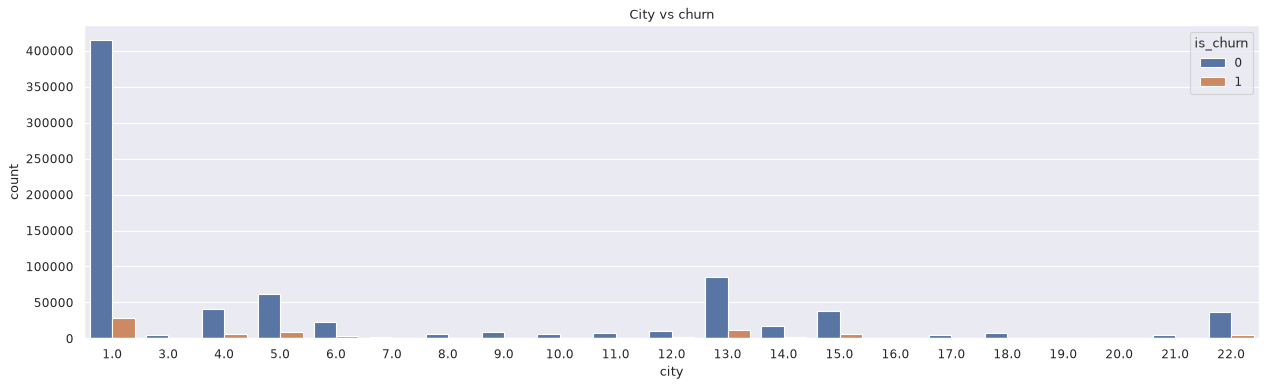

In [78]:
figure(num=None, figsize=(16, 5), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(data=train_member, x="city", hue="is_churn")
plt.title("City vs churn")
plt.xlabel("city")
plt.ylabel("count")
plt.tight_layout()
plt.show()

People in cities 4, 5, 15 and 22 have a higher churn rate. Note that city 13 has a lower churn rate than 5 and 22.

### Plot between density of age with respect to churn

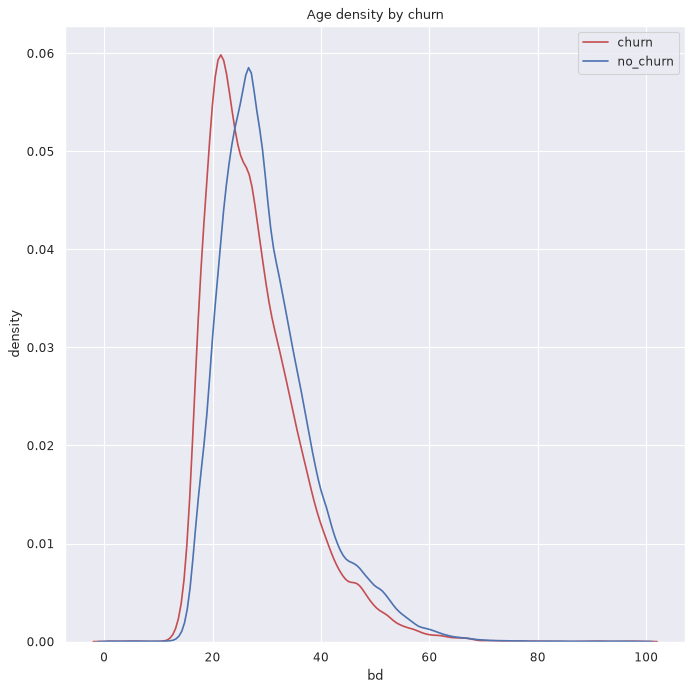

In [79]:
figure(num=None, figsize=(10, 10), dpi=80, facecolor="w", edgecolor="k")
sns.kdeplot(x=train_member["bd"][(train_member["is_churn"] == 1) & (train_member["bd"] > 0) & (train_member["bd"] < 100)], color="r", label="churn")
sns.kdeplot(x=train_member["bd"][(train_member["is_churn"] == 0) & (train_member["bd"] > 0) & (train_member["bd"] < 100)], label="no_churn")
plt.title("Age density by churn")
plt.xlabel("bd")
plt.ylabel("density")
plt.legend()
plt.show()

The plot shows that teenagers tend to churn more. This is not significantly important, but it definitely has some value in differentiating.

In [80]:
# merging all three datasets: train, member and transaction
train_member_transaction = pd.merge(train_member, transaction_data, how="left", on="msno")

In [81]:
train_member_transaction.head()

,msno,is_churn,city,registered_via,bd,registration_init_time,gender,payment_method_id,payment_plan_days,plan_list_price,actual_amount_paid,is_auto_renew,transaction_date,membership_expire_date,is_cancel
0,ugx0CjOMzazClkFzU2xasmDZaoIqOUAZPsH1q0teWCg=,1,5.0,3.0,28.0,2013-12-23,male,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN
1,f/NmvEzHfhINFEYZTR05prUdr+E+3+oewvweYz9cCQE=,1,13.0,3.0,20.0,2013-12-23,male,36.0,30.0,180.0,180.0,0.0,2017-03-11,2017-04-11,0.0
2,zLo9f73nGGT1p21ltZC3ChiRnAVvgibMyazbCxvWPcg=,1,13.0,3.0,18.0,2013-12-27,male,17.0,60.0,0.0,0.0,0.0,2017-03-11,2017-03-14,0.0
3,zLo9f73nGGT1p21ltZC3ChiRnAVvgibMyazbCxvWPcg=,1,13.0,3.0,18.0,2013-12-27,male,15.0,90.0,300.0,300.0,0.0,2017-03-14,2017-06-15,0.0
4,8iF/+8HY8lJKFrTc7iR9ZYGCG2Ecrogbc2Vy5YhsfhQ=,1,1.0,7.0,0.0,2014-01-09,NaN,41.0,30.0,149.0,149.0,1.0,2015-09-08,2017-06-08,0.0


### Plot between density of price (actual) with respect to churn

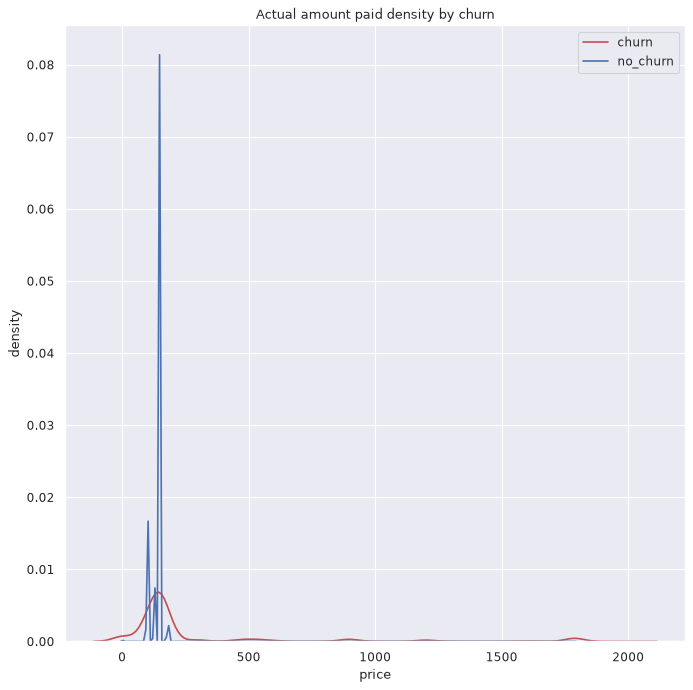

In [82]:
figure(num=None, figsize=(10, 10), dpi=80, facecolor="w", edgecolor="k")
sns.kdeplot(x=train_member_transaction["actual_amount_paid"][train_member_transaction["is_churn"] == 1], color="r", label="churn")
sns.kdeplot(x=train_member_transaction["actual_amount_paid"][train_member_transaction["is_churn"] == 0], label="no_churn")
plt.title("Actual amount paid density by churn")
plt.xlabel("price")
plt.ylabel("density")
plt.legend()
plt.show()

**Bivariate.**

- `gender` barely influences churn. `registered_via = 9` and cities 4, 5, 15 and 22 have more churn. Young users churn slightly more.
- In the pairplot, churn and no-churn overlap, so no raw variable separates the classes well.

In [83]:
# Only for visualization
df_plot = train_member_transaction.drop(columns=["registration_init_time", "transaction_date", "membership_expire_date"]).copy()
df_plot = df_plot.dropna()
df_plot = df_plot.sort_values(by="is_churn", ascending=False).reset_index(drop=True)

### Pair plots

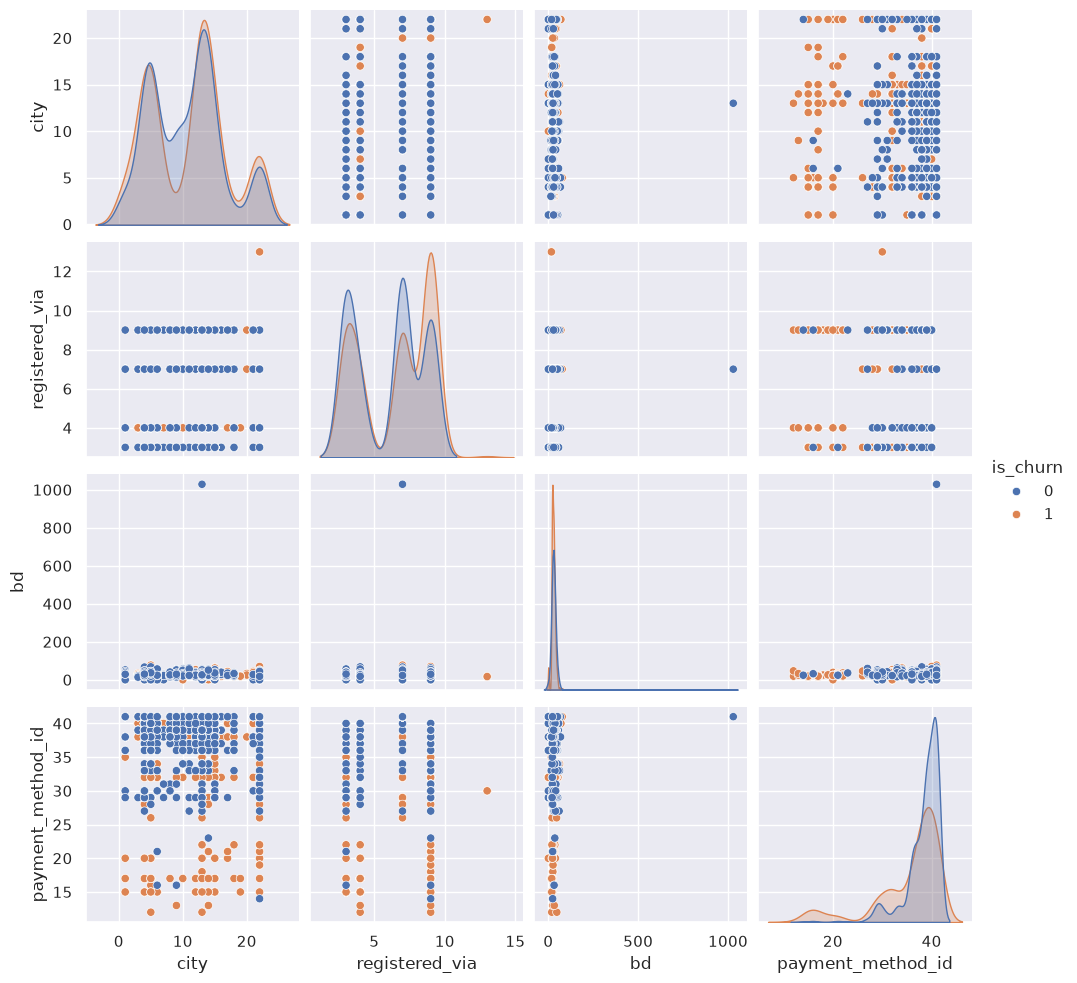

In [84]:
%matplotlib inline
sns.pairplot(data=df_plot[57380:59380].iloc[:, :7], hue="is_churn")

We can see that both churned and not-churned customers almost overlap. It is very difficult to tell which customer will churn with these features; we have to come up with different features that best differentiate both classes. Clearly there are some outliers.

## 7. Conclusions

1. The classes are imbalanced.
2. `bd` and `registered_via` must be cleaned and `gender` discarded.
3. The difference between the list price and the amount paid is a feature.
4. The logs need outlier clipping.
5. Time carries information and must be encoded into features.
6. The signal is spread across variables, so the key is feature engineering and boosting models.

# Next part is of Data Cleaning and Preprocessing

> A Clean Place is a safe place